<a href="https://colab.research.google.com/github/KateT840/Espectrografia-astronomica/blob/main/Procesamiento_y_extracci%C3%B3n_del_perfil_de_un_espectro_solar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt

# Subir la imagen solar y el dark
archivos = files.upload()

Saving sol ha derecha 20 seg.FIT to sol ha derecha 20 seg.FIT
Saving Imagen oscura 20s.FIT to Imagen oscura 20s.FIT


In [2]:
# Ver qué archivos se subieron
print(archivos.keys())

dict_keys(['sol ha derecha 20 seg.FIT', 'Imagen oscura 20s.FIT'])


In [3]:
nombre_solar = 'sol ha derecha 20 seg.FIT'
nombre_dark = 'Imagen oscura 20s.FIT'

with fits.open(nombre_solar) as hdul:
    solar = hdul[0].data.astype(float)

with fits.open(nombre_dark) as hdul:
    dark = hdul[0].data.astype(float)

print("Solar:", solar.shape)
print("Dark:", dark.shape)

Solar: (1020, 1530)
Dark: (1020, 1530)


In [4]:
solar_corregido = solar - dark

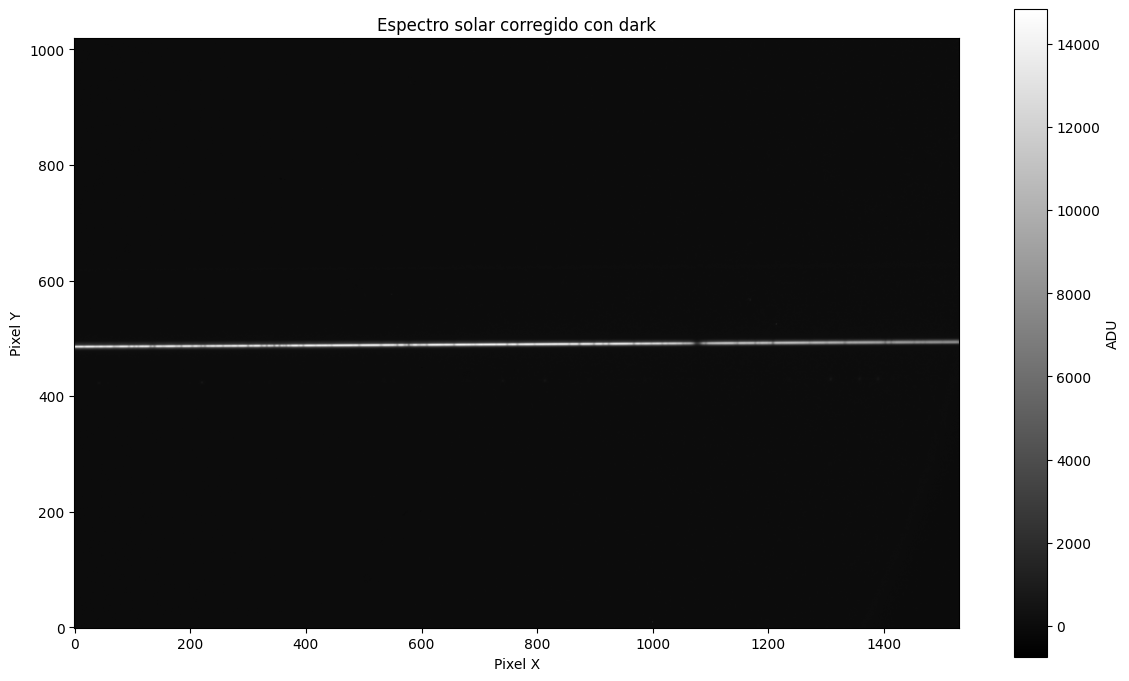

In [6]:
plt.figure(figsize=(12, 7))

plt.imshow(solar_corregido, cmap='gray', origin='lower')
plt.xlabel('Pixel X')
plt.ylabel('Pixel Y')
plt.title('Espectro solar corregido con dark')
plt.colorbar(label='ADU')

plt.tight_layout()

plt.savefig('espectro_corregido.png', dpi=300, bbox_inches='tight')
plt.show()

#from google.colab import files
#files.download('espectro_corregido.png')

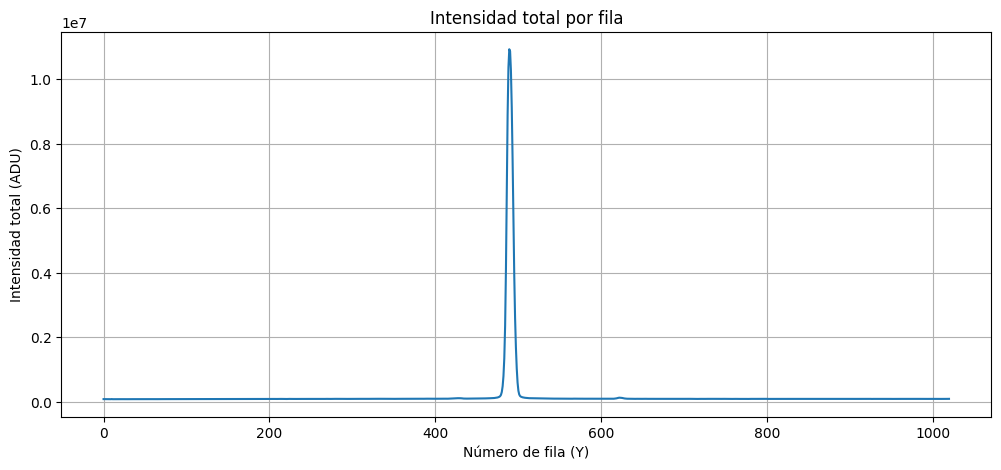

In [7]:
# Sumar la intensidad de cada fila
intensidad_filas = np.sum(solar_corregido, axis=1)

plt.figure(figsize=(12, 5))
plt.plot(intensidad_filas)

plt.xlabel('Número de fila (Y)')
plt.ylabel('Intensidad total (ADU)')
plt.title('Intensidad total por fila')

plt.grid()
plt.savefig('localizacion_espectro.png', dpi=300, bbox_inches='tight')
plt.show()

#files.download('localizacion_espectro.png')

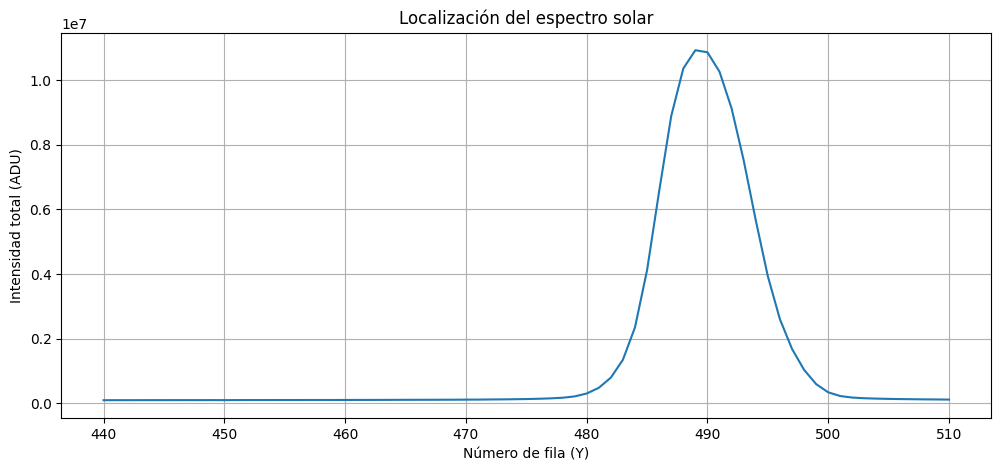

In [8]:
plt.figure(figsize=(12, 5))

plt.plot(
    np.arange(440, 511),
    intensidad_filas[440:511]
)

plt.xlabel('Número de fila (Y)')
plt.ylabel('Intensidad total (ADU)')
plt.title('Localización del espectro solar')

plt.grid()
plt.show()

In [9]:
region = intensidad_filas[440:511]

fila_max = np.argmax(region) + 440

print("Fila donde está el máximo:", fila_max)

Fila donde está el máximo: 489


In [10]:
y_centro = 489

y_inicio = y_centro - 5
y_final = y_centro + 6

print("Filas utilizadas:", y_inicio, "a", y_final - 1)

Filas utilizadas: 484 a 494


In [11]:
perfil = np.sum(
    solar_corregido[y_inicio:y_final, :],
    axis=0
)

print("Número de puntos del perfil:", len(perfil))

Número de puntos del perfil: 1530


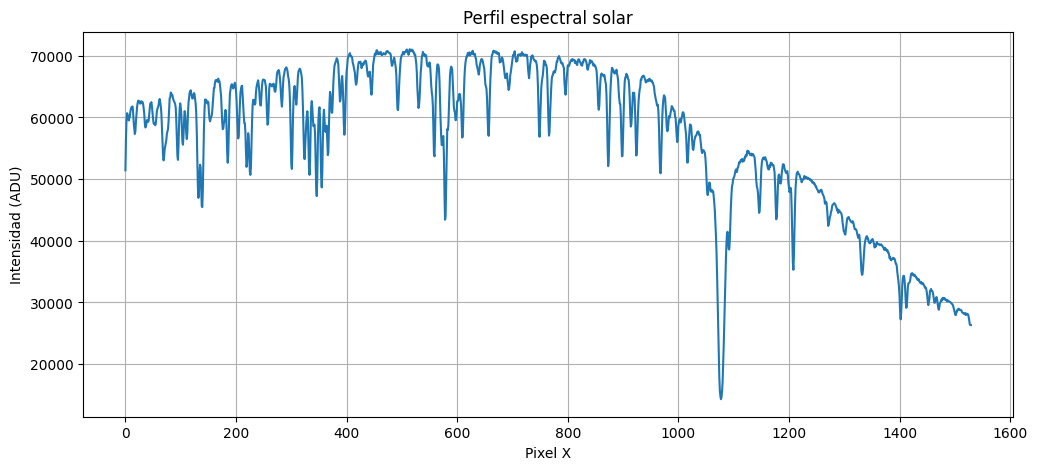

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(perfil)

plt.xlabel('Pixel X')
plt.ylabel('Intensidad (ADU)')
plt.title('Perfil espectral solar')

plt.grid()
plt.savefig('perfil_espectral.png', dpi=300, bbox_inches='tight')
plt.show()

#files.download('perfil_espectral.png')

In [13]:
perfil_normalizado = perfil / np.max(perfil)

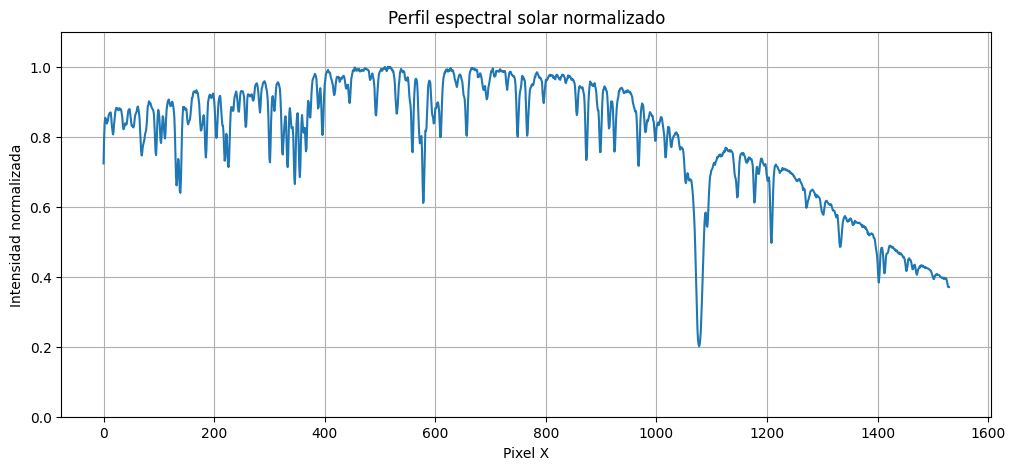

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(perfil_normalizado)

plt.xlabel('Pixel X')
plt.ylabel('Intensidad normalizada')
plt.title('Perfil espectral solar normalizado')

plt.ylim(0, 1.1)
plt.grid()
plt.savefig('perfil_espectral_normalizado.png', dpi=300, bbox_inches='tight')
plt.show()

#files.download('perfil_espectral_normalizado.png')

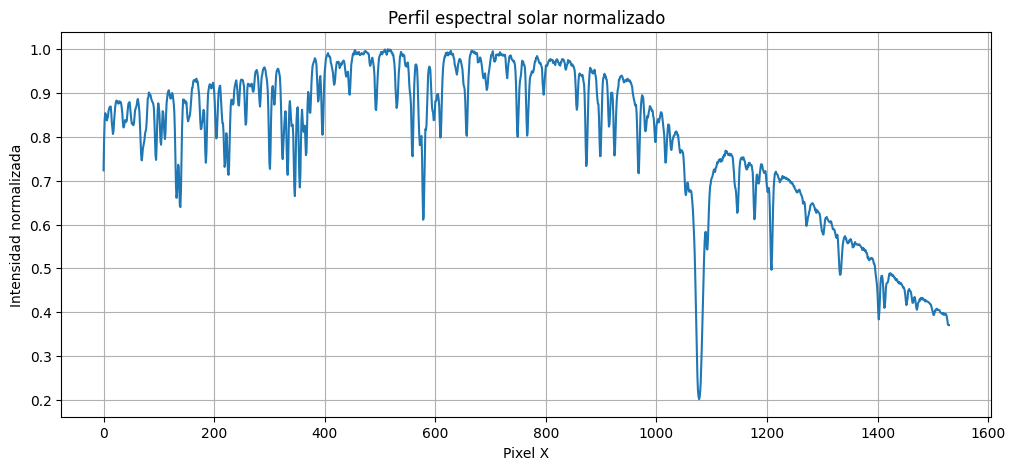

In [15]:
plt.figure(figsize=(12, 5))

plt.plot(perfil_normalizado)

plt.xlabel('Pixel X')
plt.ylabel('Intensidad normalizada')
plt.title('Perfil espectral solar normalizado')

plt.grid()
plt.savefig('perfil_espectral_normalizado.png', dpi=300, bbox_inches='tight')
plt.show()

#files.download('perfil_espectral_normalizado.png')

In [16]:
region = perfil_normalizado[950:1251]

pixel_min = np.argmin(region) + 950
valor_min = np.min(region)

print("Pixel del mínimo:", pixel_min)
print("Intensidad mínima:", valor_min)

Pixel del mínimo: 1077
Intensidad mínima: 0.20128627318528525


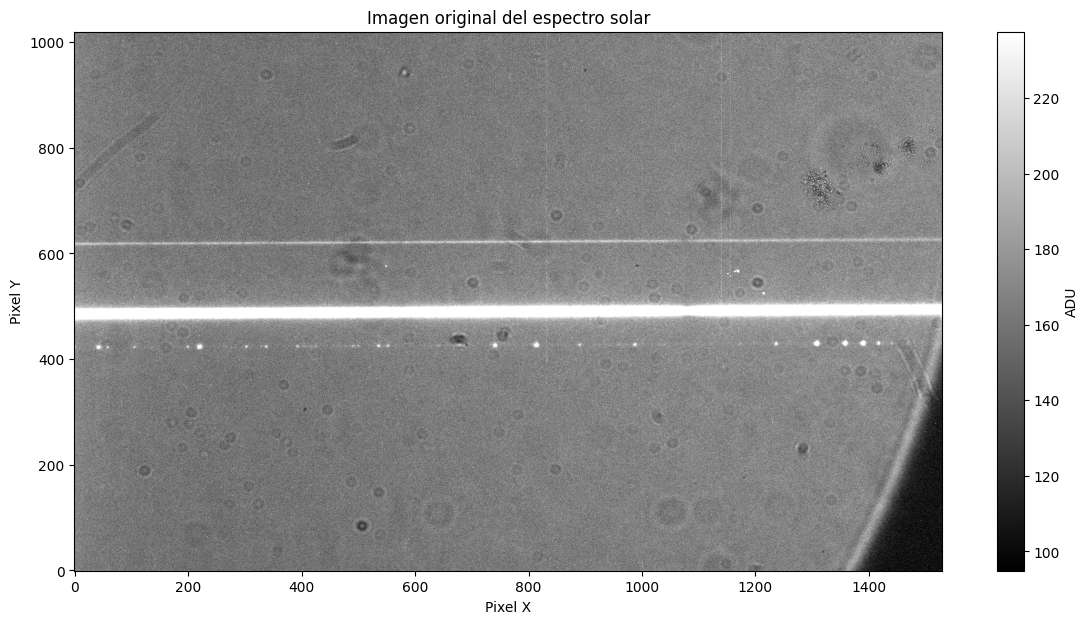

In [20]:

from astropy.visualization import ZScaleInterval

intervalo = ZScaleInterval()
vmin, vmax = intervalo.get_limits(solar)

plt.figure(figsize=(14, 7))
plt.imshow(
    solar,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax,
    aspect="auto"
)

plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")
plt.title("Imagen original del espectro solar")
plt.colorbar(label="ADU")
plt.show()


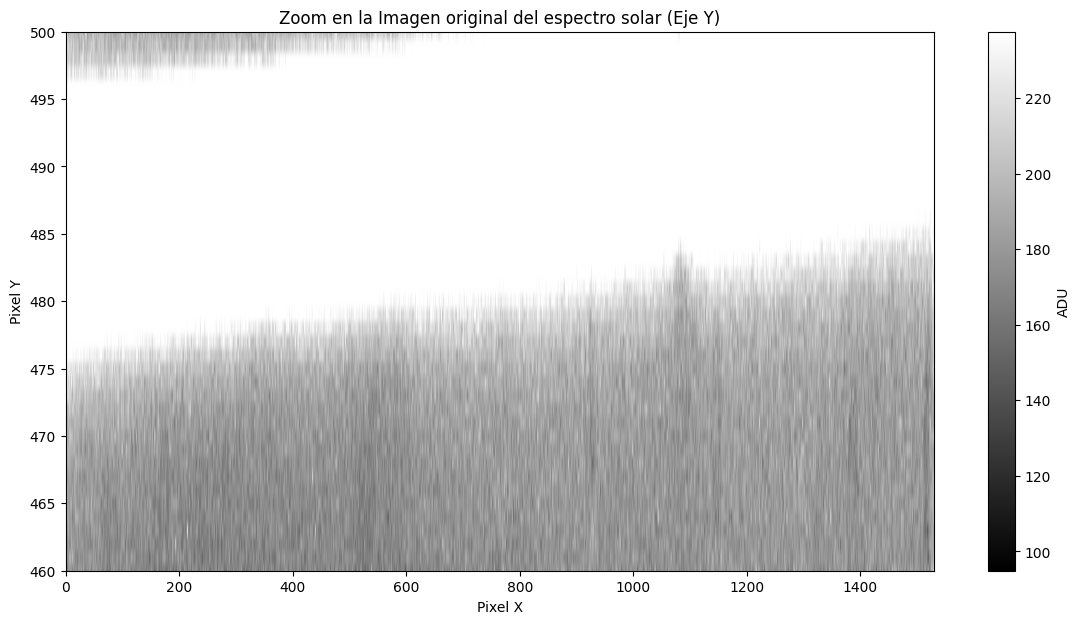

In [89]:
from astropy.visualization import ZScaleInterval
import matplotlib.pyplot as plt

intervalo = ZScaleInterval()
vmin, vmax = intervalo.get_limits(solar)

plt.figure(figsize=(14, 7))
plt.imshow(
    solar, cmap="gray", origin="lower", vmin=vmin, vmax=vmax, aspect="auto"
)

# === AQUÍ HACES EL ZOOM EN EL EJE Y ===
# Reemplaza 400 y 550 por el rango de filas exacto donde se ve tu espectro
plt.ylim(460, 500)

# Opcional: si también quieres limitar el eje X, puedes descomentar la siguiente línea:
# plt.xlim(0, 2000)

plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")
plt.title(
    "Zoom en la Imagen original del espectro solar (Eje Y)"
)  #'
plt.colorbar(label="ADU")
plt.show()

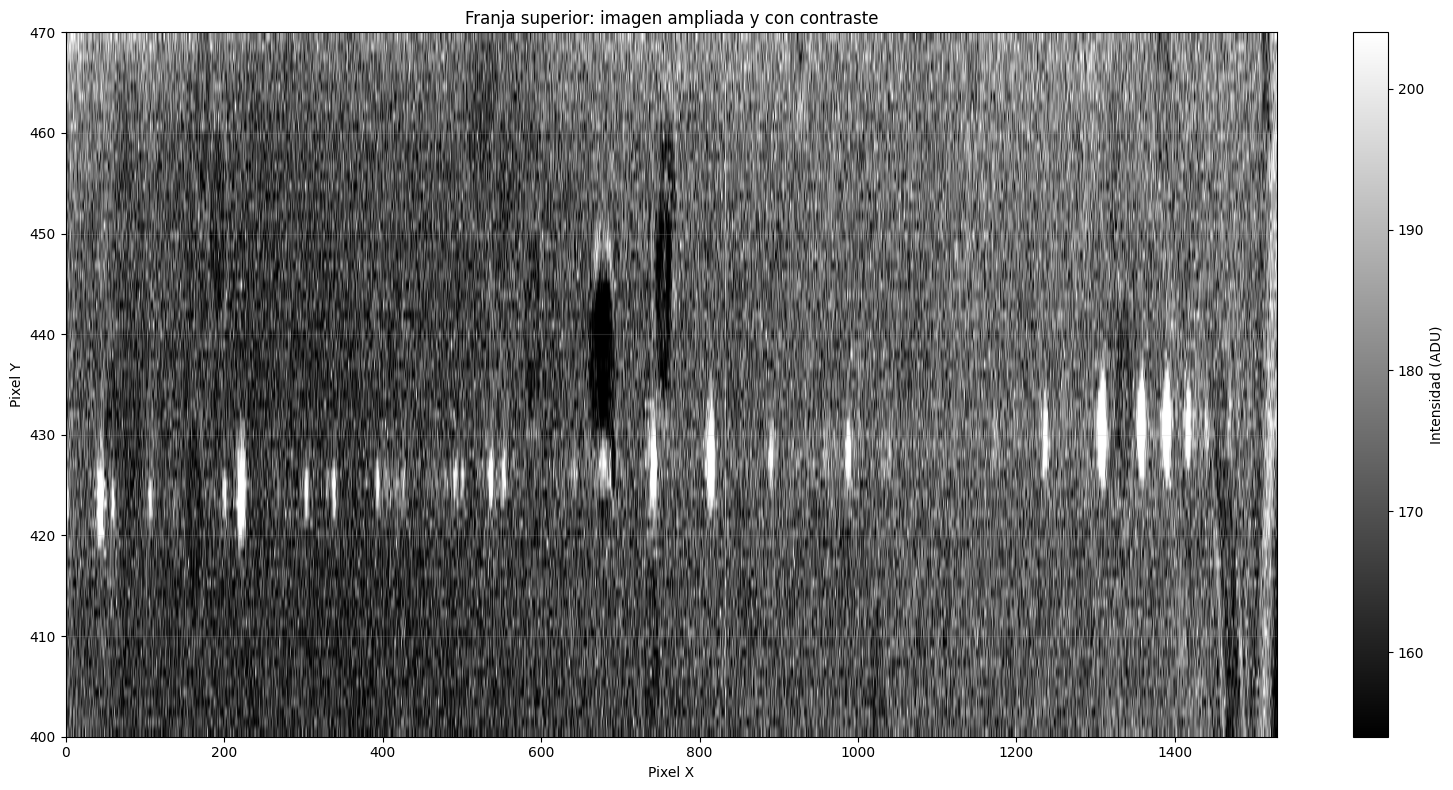

In [91]:
zona = solar[400:471, :]

vmin, vmax = np.percentile(zona, [5, 99])

plt.figure(figsize=(16, 8))
plt.imshow(
    zona,
    cmap="gray",
    origin="lower",
    aspect="auto",
    extent=[0, solar.shape[1] - 1, 400, 470],
    vmin=vmin,
    vmax=vmax
)

plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")
plt.title("Franja superior: imagen ampliada y con contraste")
plt.colorbar(label="Intensidad (ADU)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

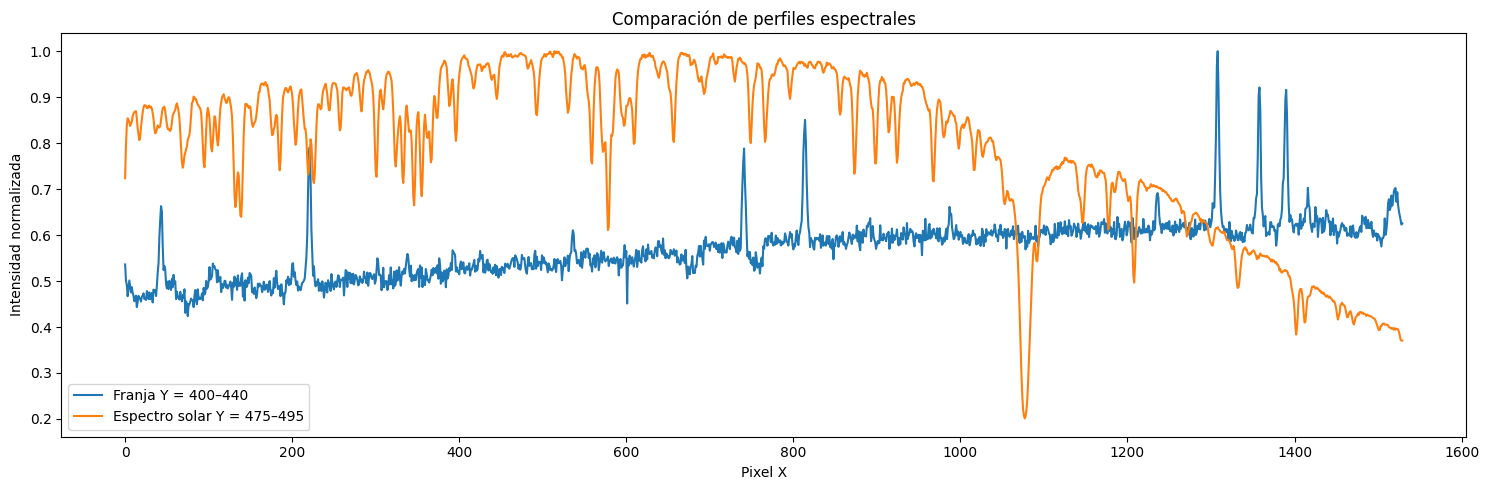

Pixel | Candidata | Solar
  220 |    0.7754 |    0.7402
  221 |    0.7913 |    0.7713
  222 |    0.7227 |    0.8083
  741 |    0.7882 |    0.9723
  813 |    0.8238 |    0.9684
  814 |    0.8506 |    0.9720
 1307 |    0.9677 |    0.6148
 1308 |    1.0000 |    0.6171
 1309 |    0.9128 |    0.6126
 1357 |    0.9032 |    0.5496
 1358 |    0.9211 |    0.5552
 1359 |    0.8722 |    0.5599
 1389 |    0.8934 |    0.5240
 1390 |    0.9159 |    0.5219


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [94]:
perfil_candidato = np.sum(solar_corregido[400:471, :], axis=0)
perfil_solar = np.sum(solar_corregido[484:495, :], axis=0)

# Normalizar cada perfil para comparar sus formas
perfil_candidato_norm = (
    perfil_candidato / np.max(np.abs(perfil_candidato))
)
perfil_solar_norm = perfil_solar / np.max(np.abs(perfil_solar))

plt.figure(figsize=(15, 5))
plt.plot(perfil_candidato_norm, label="Franja Y = 400–440")
plt.plot(perfil_solar_norm, label="Espectro solar Y = 475–495")
plt.xlabel("Pixel X")
plt.ylabel("Intensidad normalizada")
plt.title("Comparación de perfiles espectrales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.grid()
plt.savefig('Comparación_de_perfiles_espectrales.png', dpi=300, bbox_inches='tight')
plt.show()

# Intensidades de referencia en algunos píxeles candidatos
print("Pixel | Candidata | Solar")
for x in [220, 221, 222, 741, 813, 814, 1307, 1308, 1309,
          1357, 1358, 1359, 1389, 1390]:
    print(f"{x:5d} | {perfil_candidato_norm[x]:9.4f} | "
          f"{perfil_solar_norm[x]:9.4f}")

#files.download('Comparación_de_perfiles_espectrales.png')


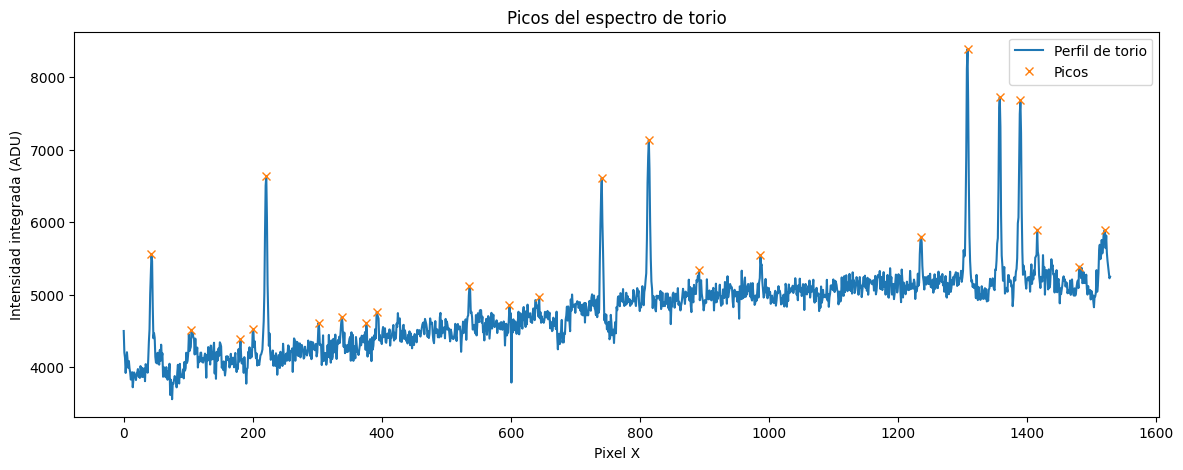

Píxel | Intensidad | Prominencia
   43 |    5560.00 |    1841.00
  105 |    4512.00 |     743.00
  181 |    4381.00 |     545.00
  201 |    4519.00 |     500.00
  221 |    6637.00 |    2853.00
  302 |    4608.00 |     582.00
  338 |    4688.00 |     608.00
  376 |    4608.00 |     524.00
  392 |    4755.00 |     546.00
  536 |    5120.00 |    1228.00
  598 |    4849.00 |     553.00
  644 |    4970.00 |     727.00
  741 |    6611.00 |    2281.00
  814 |    7134.00 |    2543.00
  892 |    5340.00 |     674.00
  987 |    5546.00 |     775.00
 1236 |    5798.00 |     841.00
 1308 |    8387.00 |    3563.00
 1358 |    7725.00 |    2821.00
 1390 |    7682.00 |    2843.00
 1416 |    5894.00 |     855.00
 1481 |    5386.00 |     508.00
 1521 |    5889.00 |     665.00


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [95]:
from scipy.signal import find_peaks

perfil_torio = np.sum(solar_corregido[400:471, :], axis=0)

picos, propiedades = find_peaks(
    perfil_torio,
    prominence=500,
    distance=3
)

plt.figure(figsize=(14, 5))
plt.plot(perfil_torio, label="Perfil de torio")
plt.plot(picos, perfil_torio[picos], "x", label="Picos")
plt.xlabel("Pixel X")
plt.ylabel("Intensidad integrada (ADU)")
plt.title("Picos del espectro de torio")
plt.legend()
plt.grid(alpha=0.3)
plt.grid()
plt.savefig('Perfil_de_torio.png', dpi=300, bbox_inches='tight')
plt.show()

print("Píxel | Intensidad | Prominencia")
for i in np.argsort(picos):
    print(
        f"{picos[i]:5d} | "
        f"{perfil_torio[picos[i]]:10.2f} | "
        f"{propiedades['prominences'][i]:10.2f}"
    )
#files.download('Perfil_de_torio.png')

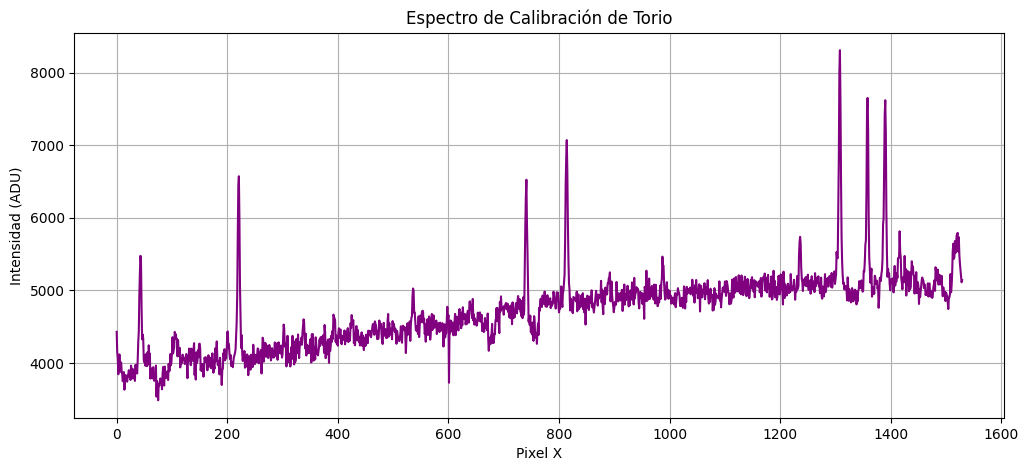

In [47]:
# Extraer y sumar la región del Torio (filas 400 a 470)
torio_perfil = np.sum(solar_corregido[400:470, :], axis=0)

# Graficar el perfil de Torio para identificar la posición en píxeles de los picos de emisión
plt.figure(figsize=(12, 5))
plt.plot(torio_perfil, color="purple")
plt.xlabel("Pixel X")
plt.ylabel("Intensidad (ADU)")
plt.title("Espectro de Calibración de Torio")
plt.grid()
plt.show()

In [60]:
torio_perfil = np.sum(solar_corregido[400:470, :], axis=0)

# Encontrar los píxeles de los picos principales
picos_pixeles, _ = find_peaks(
    torio_perfil, height=np.max(torio_perfil) * 0.15, distance=15
)
print("Píxeles donde hay picos de Torio:", picos_pixeles)

Píxeles donde hay picos de Torio: [   5   26   43   58   87  105  122  140  166  181  201  221  247  264
  286  302  318  338  353  376  392  409  425  455  475  491  518  536
  553  570  598  626  644  671  695  711  726  741  759  774  790  814
  832  859  876  892  918  936  958  987 1010 1026 1041 1069 1084 1103
 1125 1149 1172 1188 1206 1236 1263 1293 1308 1325 1343 1358 1375 1390
 1416 1438 1457 1481 1498 1521]


In [61]:
pixels_torio = np.array([43, 221, 536, 741, 814, 1308, ])
lambdas_torio = np.array([6506.98702, 6515.875, 6534.6056, 6543.893, 6547.720, 6575.139 ])

# Ajuste polinómico (por lo general de grado 2 o 3)
coefs = np.polyfit(pixels_torio, lambdas_torio, deg=2)
calibracion_lambda = np.poly1d(coefs)

# Generar el eje de longitud de onda para CADA píxel de la imagen
x_vals = np.arange(solar_corregido.shape[1])
wavelengths = calibracion_lambda(x_vals)

Píxel exacto del mínimo de H-alfa: 1072
Longitud de onda observada: 6562.204 Å
Velocidad radial del Sol estimada: -27.22 km/s


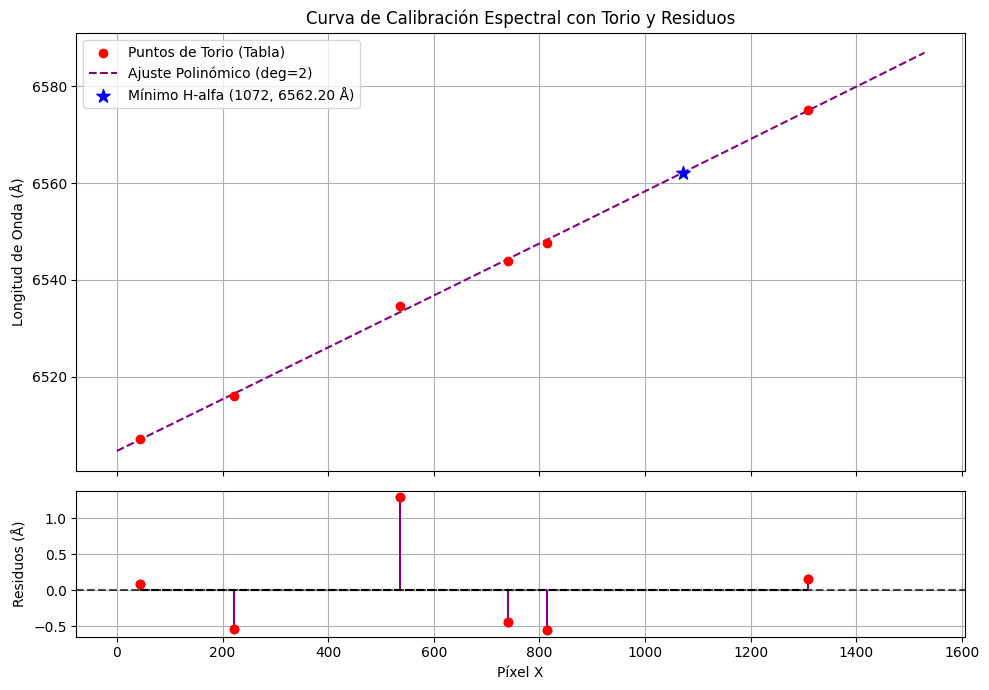

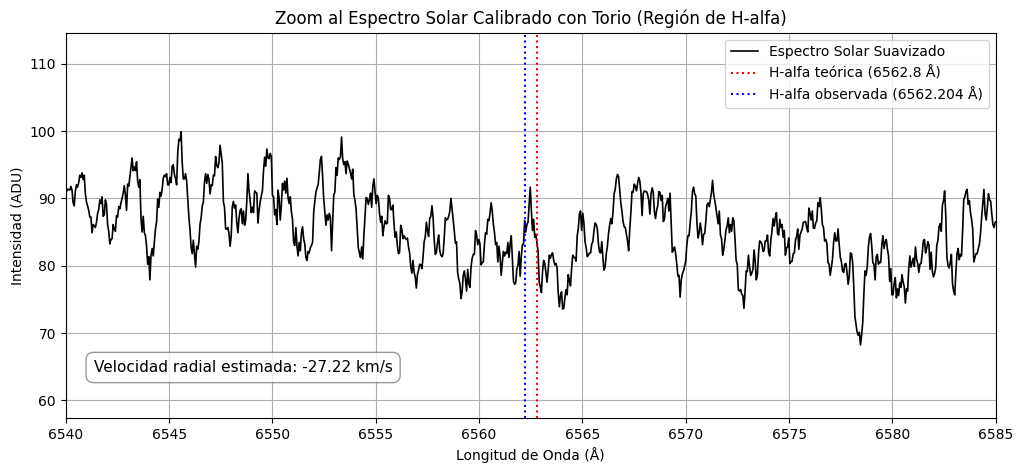

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [100]:
# 1. CÁLCULO PREVIO DE LA LÍNEA H-ALFA
fila_solar = 475
espectro_solar = solar_corregido[fila_solar, :]

region_h_alpha = np.argmin(espectro_solar[1070:1085])
pixel_minimo_h_alpha = 1070 + region_h_alpha

lambda_obs = wavelengths[pixel_minimo_h_alpha]
lambda_teorica = 6562.8  # Å

c = 299792.458  # km/s
v_doppler = c * (lambda_obs - lambda_teorica) / lambda_teorica

print(f"Píxel exacto del mínimo de H-alfa: {pixel_minimo_h_alpha}")
print(f"Longitud de onda observada: {lambda_obs:.3f} Å")
print(f"Velocidad radial del Sol estimada: {v_doppler:.2f} km/s")


# 2. CURVA DE CALIBRACIÓN Y GRÁFICO DE RESIDUOS (2 PANELES)
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)

# Panel Superior: Calibración con Torio
ax1.scatter(
    pixels_torio,
    lambdas_torio,
    color="red",
    label="Puntos de Torio (Tabla)",
    zorder=5,
)
ax1.plot(
    x_vals,
    wavelengths,
    color="purple",
    linestyle="--",
    label="Ajuste Polinómico (deg=2)",
)
ax1.scatter(
    [pixel_minimo_h_alpha],
    [lambda_obs],
    color="blue",
    s=100,
    marker="*",
    label=f"Mínimo H-alfa ({pixel_minimo_h_alpha}, {lambda_obs:.2f} Å)",
    zorder=6,
)
ax1.set_ylabel("Longitud de Onda (Å)")
ax1.set_title("Curva de Calibración Espectral con Torio y Residuos")
ax1.legend(loc="upper left")
ax1.grid()

# Calcular los residuos (Valor teórico - Valor predicho por el polinomio)
lambdas_predichas = calibracion_lambda(pixels_torio)
residuos = lambdas_torio - lambdas_predichas



# Panel Inferior: Gráfico de Residuos
ax2.axhline(0, color="black", linestyle="--", alpha=0.7)
ax2.scatter(pixels_torio, residuos, color="red", zorder=5)
ax2.stem(
    pixels_torio,
    residuos,
    linefmt="purple",
    markerfmt="ro",
    basefmt="k--",
)
ax2.set_xlabel("Píxel X")
ax2.set_ylabel("Residuos (Å)")
ax2.grid()

plt.tight_layout()
plt.savefig('Curva_de_Calibración_Espectral_con_Torio_y_Residuos.png', dpi=300, bbox_inches='tight')
plt.show()

# 3. ESPECTRO SOLAR CALIBRADO, SUAVIZADO Y ZOOM
def suavizar(y, ventana=5):
    box = np.ones(ventana) / ventana
    return np.convolve(y, box, mode="same")


espectro_suavizado = suavizar(espectro_solar, ventana=9)

plt.figure(figsize=(12, 5))
plt.plot(
    wavelengths,
    espectro_suavizado,
    color="black",
    lw=1.2,
    label="Espectro Solar Suavizado",
)

# Línea punteada roja para la teórica
plt.axvline(
    lambda_teorica, color="red", linestyle=":", label="H-alfa teórica (6562.8 Å)"
)

# Línea punteada azul para la observada
plt.axvline(
    lambda_obs,
    color="blue",
    linestyle=":",
    label=f"H-alfa observada ({lambda_obs:.3f} Å)",
)

# Aplicar zoom en la región de interés (alrededor de H-alfa)
plt.xlim(6540, 6585)

# Texto dentro de la gráfica con los resultados de velocidad
texto_resultados = f"Velocidad radial estimada: {v_doppler:.2f} km/s"

plt.gca().text(
    0.03,
    0.15,
    texto_resultados,
    transform=plt.gca().transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8, edgecolor="gray"),
)

plt.xlabel("Longitud de Onda (Å)")
plt.ylabel("Intensidad (ADU)")
plt.title("Zoom al Espectro Solar Calibrado con Torio (Región de H-alfa)")
plt.legend(loc="upper right")
plt.grid()

#plt.savefig('Zoom_al_Espectro_Solar_Calibrado_con_Torio_(Región de H-alfa).png', dpi=300, bbox_inches='tight')
plt.show()

files.download('Curva_de_Calibración_Espectral_con_Torio_y_Residuos.png')
#files.download('Zoom_al_Espectro_Solar_Calibrado_con_Torio_(Región de H-alfa).png')